# Attribution results: where the models look when they write their answer

**Models:** Qwen3-4B-Instruct-2507, Qwen2.5-Math-1.5B-Instruct, Phi-4-mini-instruct.
**Items:** test split, 2 problems per category × subtype (144 per model); only replies that finished with an
answer are used (129 / 143 / 143).

**What is explained.** The tokens of the model's **own final answer** (`Answer: y = ...`), with the model's **own
step-by-step working** in the input, exactly as it generated it. This is the setting in which the models solve the
problems; the answer-without-working control is not reported.

**Method.** **Attention** from the answer tokens to every input token, averaged over heads and layers. Attention
rollout (attention followed back through all layers) is used only in section 1, where the question is the total
flow through the network. It favours the first tokens of the input by construction, so it is not used to compare
positions. Gradient×Input and Integrated Gradients are not used for results; Appendix A shows why.

**Measure.** The problem text is split into fields: instruction, equation, each condition, answer-format
instruction. *Density* = a field's share of the attention ÷ its share of the problem's tokens (1× = in proportion to
its length). Every comparison is made **per item** and summarised by the **median with a bootstrap 95% CI**
(2000 resamples, seed 0). An interval that does not contain 1× is a clear effect.

All numbers below are computed by `attribution_report.py` in the next cells; figures and CSV tables are saved
next to the notebook and zipped at the end.

In [1]:
import glob, os, shutil, sys
INPUT = '/kaggle/input'
if os.path.isdir(INPUT):                                    # on Kaggle: copy the uploaded files to a writable folder
    found = glob.glob(os.path.join(INPUT, '**', 'attribution_report.py'), recursive=True)
    assert found, 'add the dataset made from kaggle_attribution_results_files.zip as an Input of this notebook'
    WORK = '/kaggle/working/Thesis'
    shutil.copytree(os.path.dirname(found[0]), WORK, dirs_exist_ok=True)
    os.chdir(WORK)
sys.path.insert(0, os.getcwd())
OUT = os.path.join('figures', 'attribution', 'report_a')

import pandas as pd
from IPython.display import Image, display
import attribution_report as AR
pd.set_option('display.max_colwidth', None)

R = AR.build('results/attribution', OUT)                    # all analyses, ~10-60 s on CPU
T = lambda name: pd.DataFrame(R['tables'][name])
show = lambda key, width=None: display(Image(filename=R['figures'][key], width=width))
T('runs')

,model,items with a finished answer,wrong answers,dtype,run folder
0,Qwen3-4B,129,3,float16,20261104T103549Z_qwen3-4b-instruct-2507_a_test
1,Qwen2.5-Math-1.5B,143,17,float32,20261104T185912Z_qwen2.5-math-1.5b-instruct_a_test
2,Phi-4-mini,143,39,float16,20261104T130748Z_phi-4-mini-instruct_a_test


## Key results

In [2]:
T('summary').set_index('result')

,Qwen3-4B,Qwen2.5-Math-1.5B,Phi-4-mini
result,,,
Attention on the model's own working (share),"75% [75%, 76%]","82% [81%, 82%]","79% [79%, 80%]"
Rollout on the model's own working (share),"28% [26%, 30%]","49% [47%, 50%]","29% [28%, 31%]"
"Position 2 vs 1, same role (regression)","1.06 [0.84, 1.33]","1.14 [0.96, 1.37]","1.09 [0.93, 1.28]"
"Distractor written first vs useful, same position","1.23 [0.94, 1.59]","1.34 [1.07, 1.64]","1.09 [0.90, 1.32]"
"Distractor written after a useful one vs useful, same position","0.60 [0.47, 0.74]","0.69 [0.57, 0.82]","0.74 [0.63, 0.86]"
Same condition twice: second copy ÷ first copy,"0.55 [0.50, 0.58]","0.62 [0.57, 0.64]","0.75 [0.69, 0.82]"
Wrong ÷ correct answers: attention on the equation,–,"0.94 [0.78, 1.14]","0.63 [0.53, 0.78]"
Wrong ÷ correct answers: attention on the useful conditions,–,"1.07 [0.80, 1.16]","0.76 [0.68, 0.89]"


- **The answer is read mostly from the model's own working:** 75–82% of the answer tokens' attention goes to the
  working, the rest to the problem text.
- **The distractor condition is attended less only when it is written after a useful condition** (0.60–0.74× a
  useful condition at the same position). Written first, it is not attended less (1.09–1.34×). Position on its own
  has no effect (1.06–1.14×, all intervals include 1).
- **A condition written twice:** the second copy gets 0.55–0.75× the attention of the first.
- **Phi-4-mini's wrong answers** come with less attention on the equation (0.63×) and the useful conditions (0.76×).
  Qwen2.5-Math shows no difference; Qwen3-4B has only 3 wrong answers.

## 1. Where the answer tokens look
Left: direct attention from the answer tokens to each field of the problem. Right: attention rollout, which also
counts indirect paths (answer → working → problem).

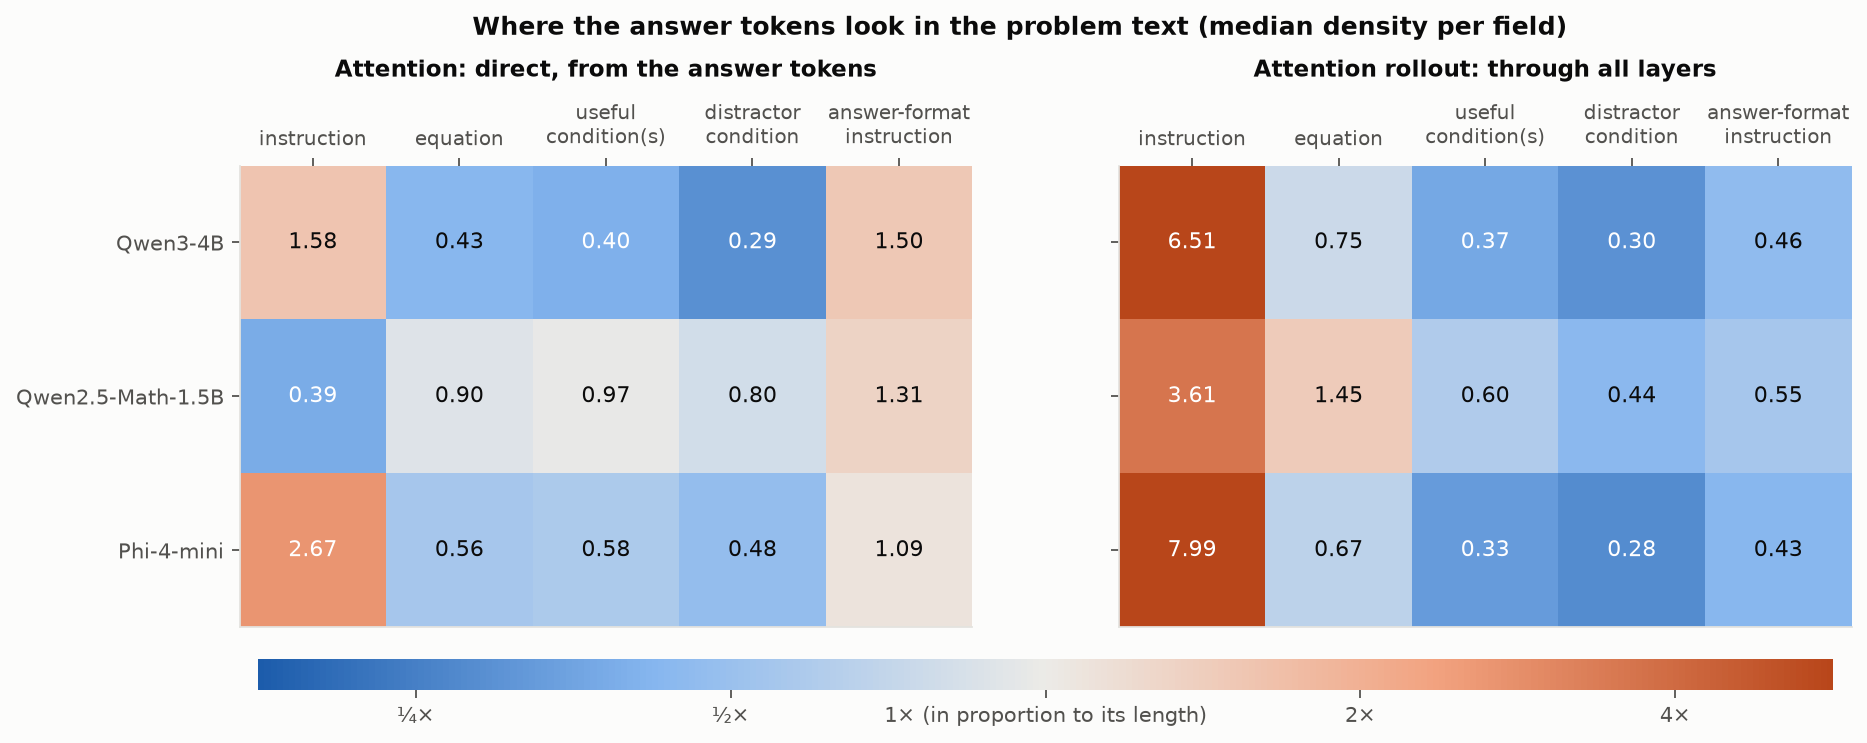

instruction           equation  \
method            model                                                     
Attention         Qwen3-4B           1.58 [1.52, 1.64]  0.43 [0.39, 0.47]   
                  Qwen2.5-Math-1.5B  0.39 [0.38, 0.40]  0.90 [0.84, 1.03]   
                  Phi-4-mini         2.67 [2.56, 2.76]  0.56 [0.50, 0.63]   
Attention rollout Qwen3-4B           6.51 [6.32, 6.76]  0.75 [0.72, 0.78]   
                  Qwen2.5-Math-1.5B  3.61 [3.51, 3.68]  1.45 [1.40, 1.49]   
                  Phi-4-mini         7.99 [7.74, 8.29]  0.67 [0.65, 0.69]   

                                    useful condition(s) distractor condition  \
method            model                                                        
Attention         Qwen3-4B            0.40 [0.37, 0.43]    0.29 [0.27, 0.33]   
                  Qwen2.5-Math-1.5B   0.97 [0.91, 1.02]    0.80 [0.72, 0.83]   
                  Phi-4-mini          0.58 [0.55, 0.63]    0.48 [0.46, 0.52]   
Attention rollout Qwen3-4B            0.37 [0.36, 0.38]    0.30 [0.28, 0.34]   
                  Qwen2.5-Math-1.5B   0.60 [0.58, 0.63]    0.44 [0.39, 0.57]   
                  Phi-4-mini          0.33 [0.30, 0.35]    0.28 [0.27, 0.32]   

                                    answer-format instruction  
method            model                                        
Attention         Qwen3-4B                  1.50 [1.46, 1.52]  
                  Qwen2.5-Math-1.5B         1.31 [1.27, 1.34]  
                  Phi-4-mini                1.09 [1.06, 1.12]  
Attention rollout Qwen3-4B                  0.46 [0.45, 0.47]  
                  Qwen2.5-Math-1.5B         0.55 [0.55, 0.56]  
                  Phi-4-mini                0.43 [0.42, 0.44]

In [3]:
show('where')
T('where').set_index(['method', 'model'])

**Results**
- Within the problem text, **Qwen3-4B and Phi-4-mini attend most to the two instructions**: instruction 1.58× and
  2.67×, answer-format instruction 1.50× and 1.09×. The equation and the conditions get less than their share
  (0.40–0.58×).
- **Qwen2.5-Math reads the problem differently:** instruction 0.39×, equation 0.90×, useful conditions 0.97×,
  answer-format instruction 1.31×.
- **The distractor is the least-attended field in every model** (0.29×, 0.80×, 0.48×).
- Rollout puts 3.6–8.0× on the instruction, the first tokens of the problem. That is rollout's known bias towards
  early tokens, not a property of the instruction.

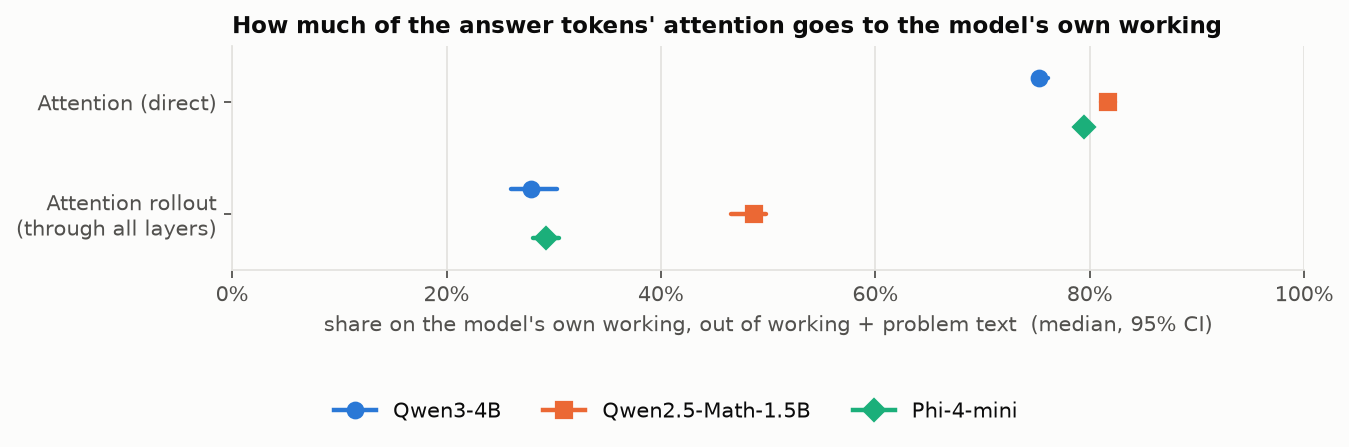

,Qwen3-4B,Qwen2.5-Math-1.5B,Phi-4-mini
method,,,
Attention,"75% [75%, 76%]","82% [81%, 82%]","79% [79%, 80%]"
Attention rollout,"28% [26%, 30%]","49% [47%, 50%]","29% [28%, 31%]"


In [4]:
show('working', 750)
T('working').set_index('method')

**Results**
- **Direct attention:** 75% (Qwen3-4B), 82% (Qwen2.5-Math), 79% (Phi-4-mini) of the answer tokens' attention goes
  to the model's own working.
- **Rollout:** 28%, 49%, 29%. Once indirect paths are counted, more of the flow ends in the problem text, because the
  working tokens themselves attend back to the problem.

## 2. The distractor condition: order matters
Each item has the useful conditions (needed for the solution) and, in three subtypes, one **distractor**:
`rescaled` (a useful condition multiplied through), `unrelated` (a condition on another variable z), or `duplicate`
(a useful condition written twice). Ratios are attention **per token**, so condition length does not matter.
The control row uses items with two useful conditions and no distractor.

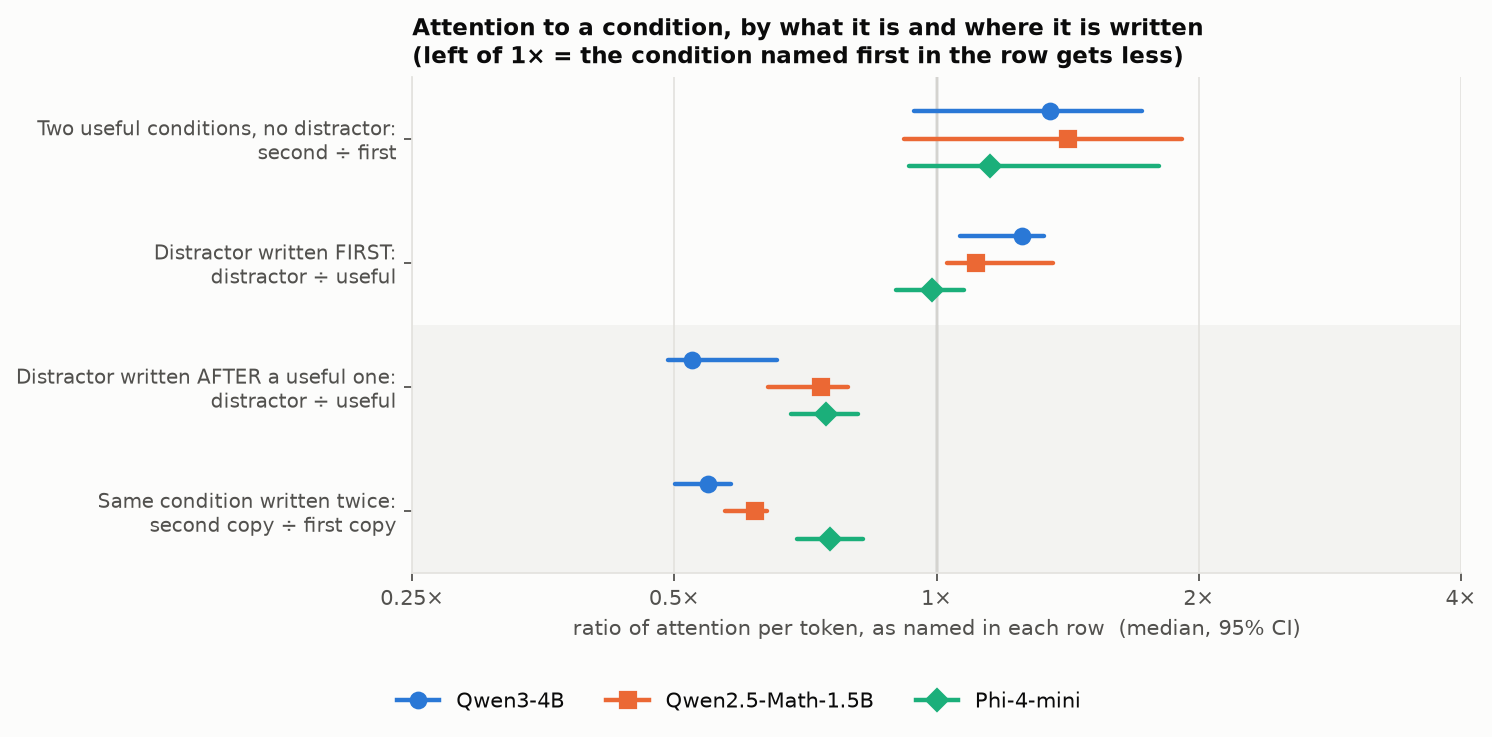

,Qwen3-4B,Qwen2.5-Math-1.5B,Phi-4-mini
case,,,
"Two useful conditions, no distractor: second ÷ first","1.35 [0.94, 1.72] (n=16)","1.41 [0.92, 1.91] (n=18)","1.15 [0.93, 1.80] (n=18)"
Distractor written FIRST: distractor ÷ useful,"1.25 [1.06, 1.33] (n=24)","1.11 [1.03, 1.36] (n=30)","0.99 [0.90, 1.07] (n=30)"
Distractor written AFTER a useful one: distractor ÷ useful,"0.52 [0.49, 0.66] (n=35)","0.74 [0.64, 0.79] (n=42)","0.75 [0.68, 0.81] (n=41)"
Same condition written twice: second copy ÷ first copy,"0.55 [0.50, 0.58] (n=36)","0.62 [0.57, 0.64] (n=35)","0.75 [0.69, 0.82] (n=36)"


In [5]:
show('order', 850)
T('order').set_index('case')

**Results**
- **Two useful conditions:** the second gets 1.15–1.41× the first; all intervals include 1.
- **Distractor written first:** 0.99–1.25× a useful condition, so it is **not** attended less.
- **Distractor written after a useful condition:** 0.52× (Qwen3-4B), 0.74× (Qwen2.5-Math), 0.75× (Phi-4-mini); all
  intervals below 1.
- **Same condition written twice:** the second copy gets 0.55×, 0.62×, 0.75× of the first; all intervals below 1.

The same split for each kind of distractor:

In [6]:
T('order_subtype').set_index(['subtype', 'distractor'])

Qwen3-4B  \
subtype   distractor                                              
rescaled  written first               1.27 [1.02, 1.42]  (n=17)   
          written after a useful one  0.50 [0.47, 0.79]  (n=17)   
unrelated written first                1.14 [0.97, 1.33]  (n=7)   
          written after a useful one  0.54 [0.49, 0.71]  (n=18)   

                                              Qwen2.5-Math-1.5B  \
subtype   distractor                                              
rescaled  written first               1.11 [1.03, 1.48]  (n=19)   
          written after a useful one  0.60 [0.46, 0.87]  (n=17)   
unrelated written first               1.16 [0.82, 1.50]  (n=11)   
          written after a useful one  0.74 [0.70, 0.86]  (n=25)   

                                                     Phi-4-mini  
subtype   distractor                                             
rescaled  written first               1.00 [0.87, 1.10]  (n=19)  
          written after a useful one  0.65 [0.54, 0.78]  (n=16)  
unrelated written first               0.97 [0.65, 1.10]  (n=11)  
          written after a useful one  0.79 [0.73, 1.10]  (n=25)

**Results:** `rescaled` and `unrelated` show the same pattern. Written first: 0.97–1.27×. Written after a useful
condition: 0.50–0.79×. (The `unrelated`-first cells have only 7–11 items.)

## 3. Position and role, separated
Section 2 compares conditions at different positions, so position and role are mixed. Here they are separated
with one regression per model: for each condition of an item, log2 attention density is modelled as

`log2 density = item effect + position (2nd, 3rd vs 1st) + role (distractor written first / distractor written after a useful one, vs useful)`

The item effect removes everything that is shared within a problem. Data: items with at least two conditions
(`none` second-order, `rescaled`, `unrelated`; `duplicate` is left out because its two copies are identical text).
CIs come from 1000 bootstrap resamples of items.

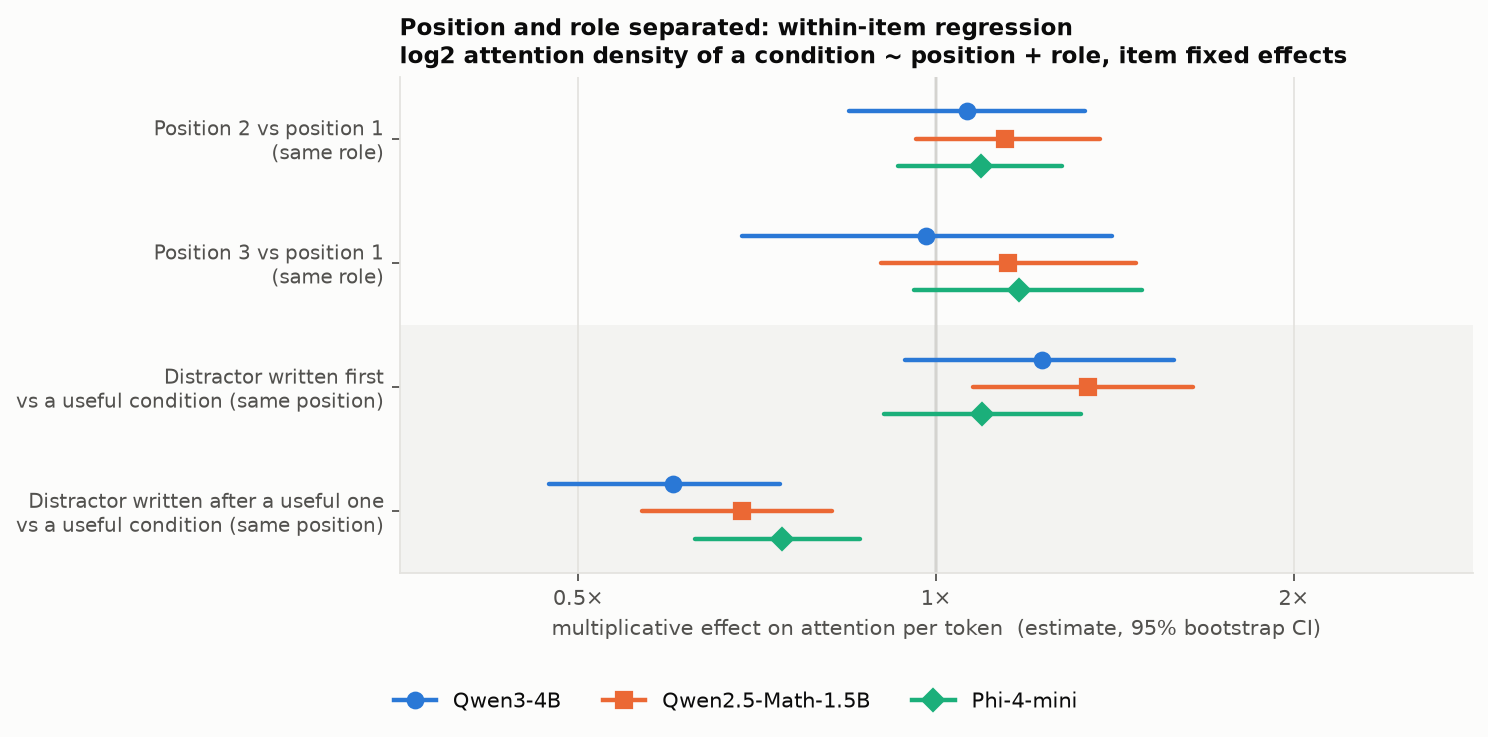

,Qwen3-4B,Qwen2.5-Math-1.5B,Phi-4-mini
effect,,,
Position 2 vs position 1 (same role),"1.06 [0.84, 1.33]","1.14 [0.96, 1.37]","1.09 [0.93, 1.28]"
Position 3 vs position 1 (same role),"0.98 [0.69, 1.41]","1.15 [0.90, 1.47]","1.17 [0.96, 1.49]"
Distractor written first vs a useful condition (same position),"1.23 [0.94, 1.59]","1.34 [1.07, 1.64]","1.09 [0.90, 1.32]"
Distractor written after a useful one vs a useful condition (same position),"0.60 [0.47, 0.74]","0.69 [0.57, 0.82]","0.74 [0.63, 0.86]"
items in the regression,75,90,89


In [7]:
show('regression', 850)
T('regression').set_index('effect')

**Results**
- **Position on its own has no clear effect:** position 2 vs 1 is 1.06–1.14×, position 3 vs 1 is 0.98–1.17×; all
  intervals include 1.
- **Distractor written first, same position:** 1.23× (Qwen3-4B), 1.34× (Qwen2.5-Math, interval above 1), 1.09×
  (Phi-4-mini).
- **Distractor written after a useful one, same position:** 0.60× [0.47, 0.74], 0.69× [0.57, 0.82], 0.74×
  [0.63, 0.86]; all intervals below 1.
- So the lower attention to the distractor is **not a position effect**. It appears only when a useful condition
  comes before the distractor.

## 4. Layer by layer
Figure 5: median density of each field in each layer. Figure 6: the regression of section 3, fitted separately in
every layer, on a common relative-depth axis.

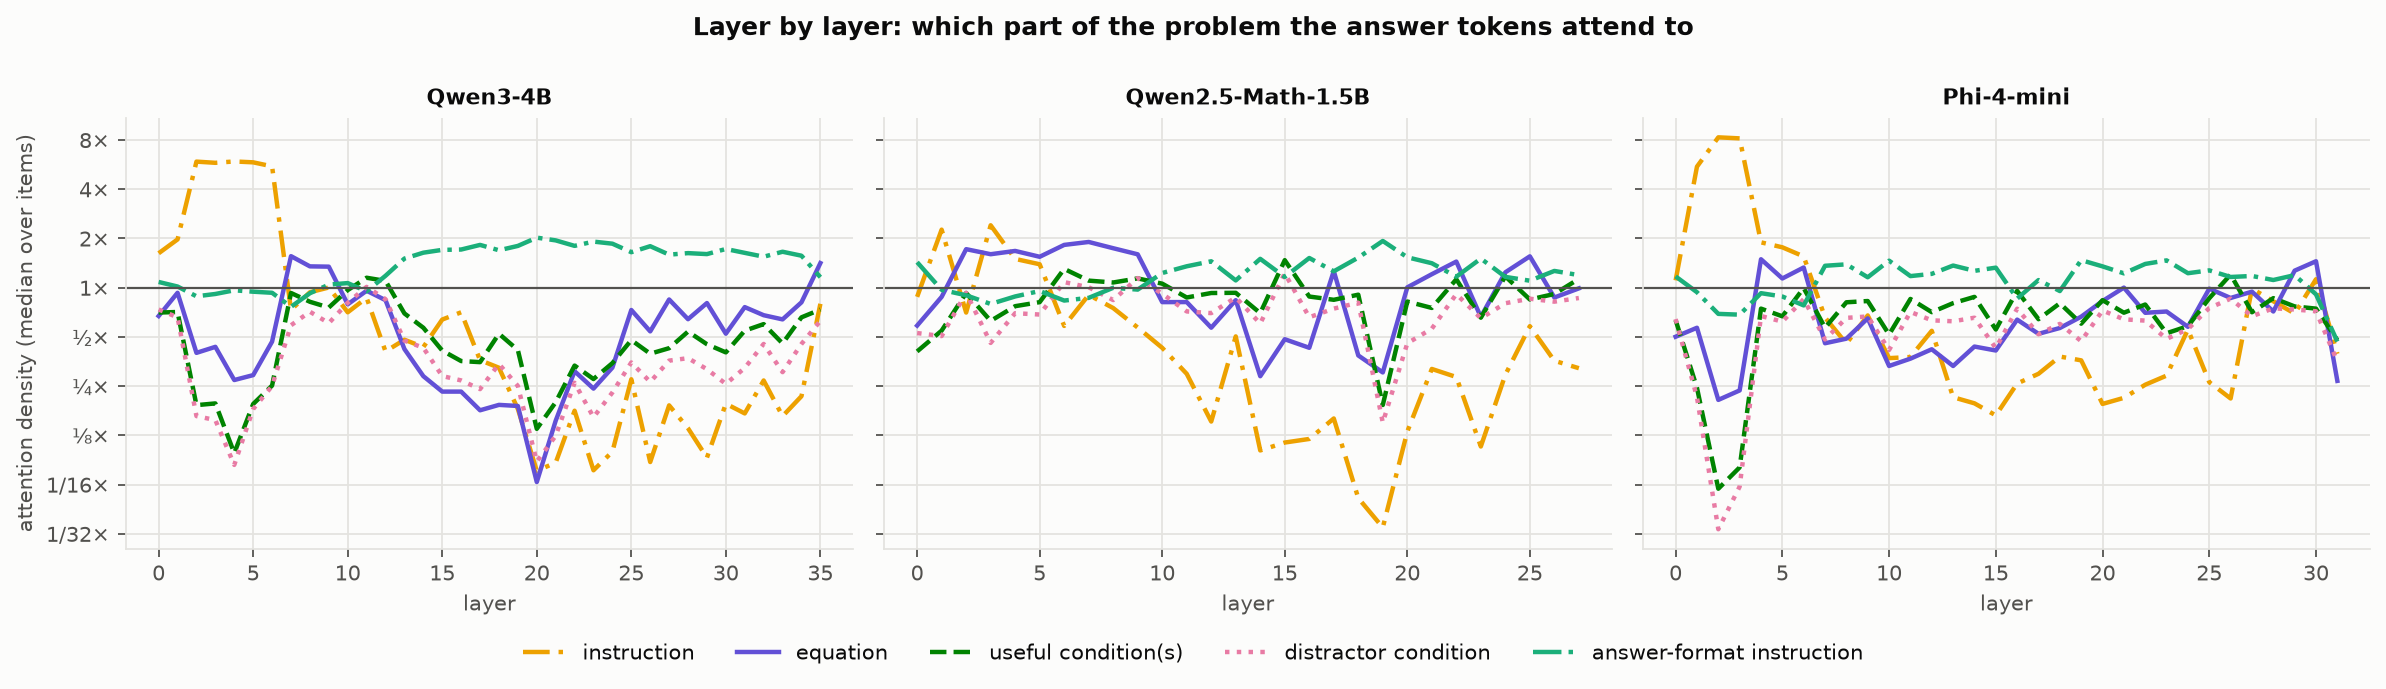

Split-half reliability of each layer profile (two random halves of the items, median of 200 splits):


,instruction,equation,useful condition(s),distractor condition,answer-format instruction
model,,,,,
Qwen3-4B,1.00,0.99,0.99,0.99,1.00
Qwen2.5-Math-1.5B,1.00,0.99,0.98,0.97,0.99
Phi-4-mini,1.00,0.98,0.99,0.99,0.99


In [8]:
show('layers')
print('Split-half reliability of each layer profile (two random halves of the items, median of 200 splits):')
T('layers_reliability').set_index('model')

**Results**
- **The profiles are reproducible:** two random halves of the items give the same layer profile (r = 0.97–1.00), so
  the jumps between neighbouring layers are properties of those layers, not noise.
- **Instruction in the early layers:** Qwen3-4B layers 2–6 (up to 5.9×), Phi-4-mini layers 1–3 (up to 8.3×),
  Qwen2.5-Math up to 2.4× (layer 3).
- **Equation in the early-middle layers:** Qwen3-4B layers 7–9 (up to 1.6×), Qwen2.5-Math layers 2–9 (up to 1.9×),
  Phi-4-mini layers 4–6 (up to 1.5×).
- **Answer-format instruction in the upper layers:** above 1.2× in Qwen3-4B layers 13–34 (up to 2.0×), most of
  Qwen2.5-Math layers 10–26 (up to 1.9×), and Phi-4-mini layers 7–25 (up to 1.5×).

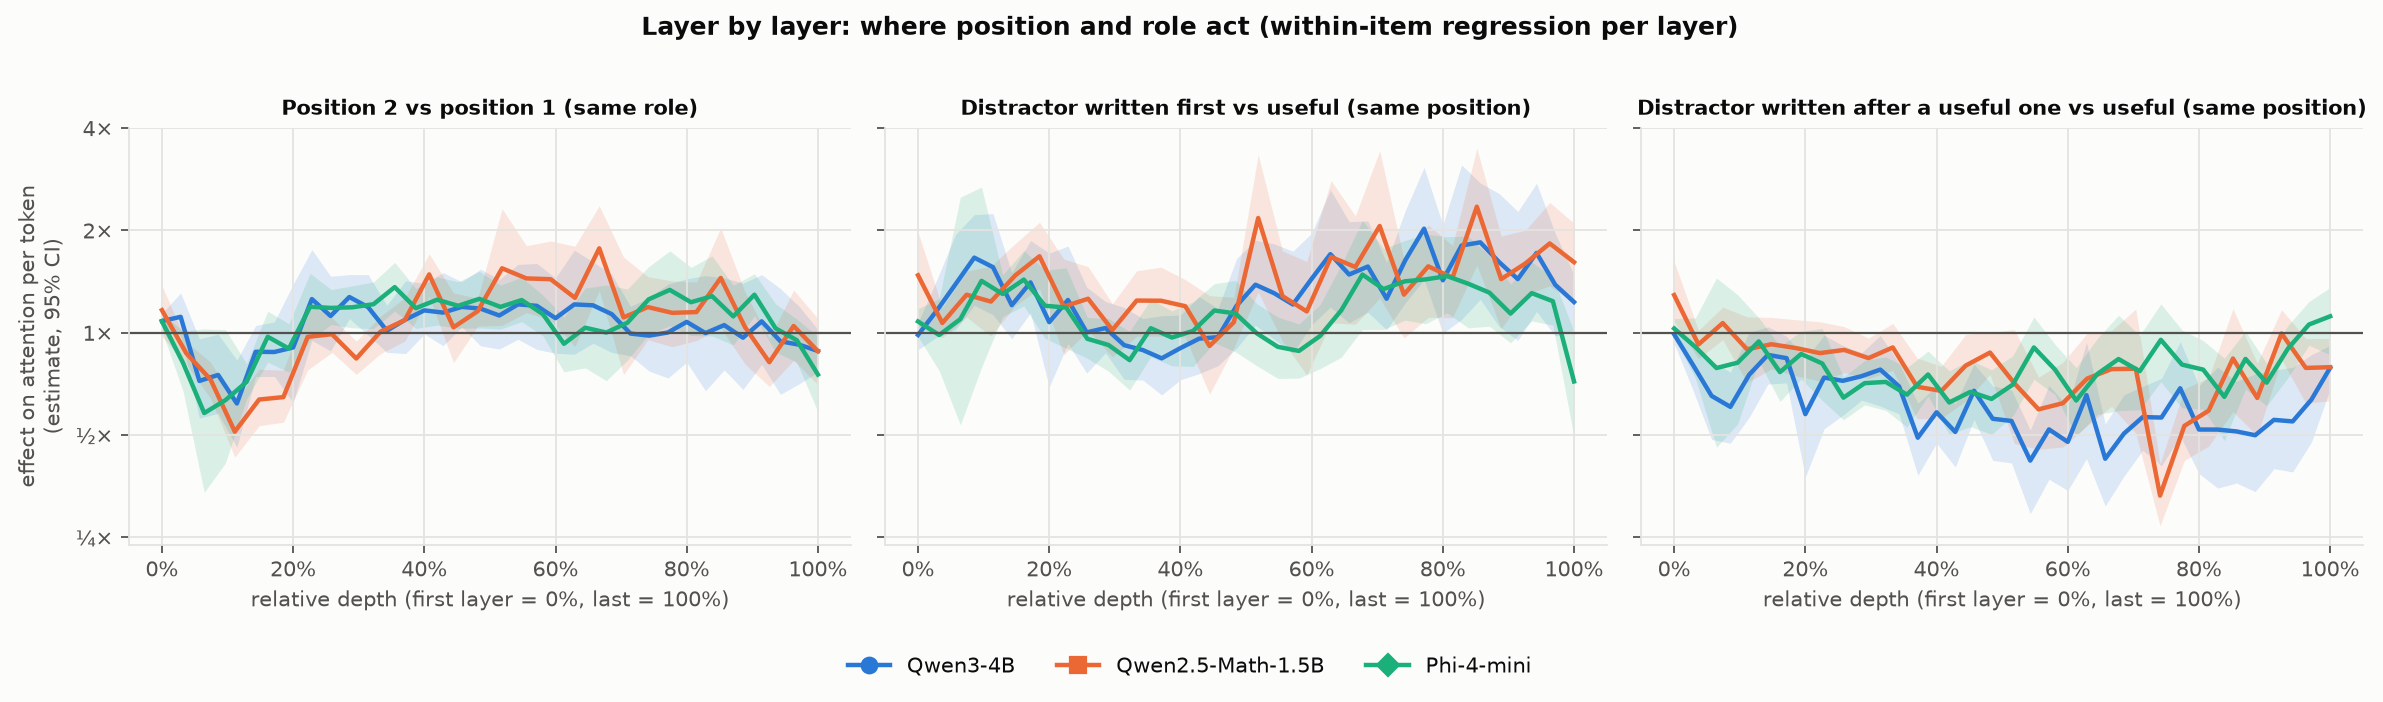

In [9]:
show('layers_effects')

**Results**
- **Position:** in the first ~5–15% of the layers, a later condition gets 0.51–0.62× the attention of an earlier one
  (the early layers favour earlier text). From about 25% depth on, the median effect is 1.12–1.19×.
- **Distractor written after a useful one:** below 1× from about 20–25% depth on. Median over the layers past 25%
  depth: 0.56× (Qwen3-4B), 0.78× (Qwen2.5-Math), 0.76× (Phi-4-mini). The lowest values are 0.42× (Qwen3-4B, layer 19,
  54% depth), 0.33× (Qwen2.5-Math, layer 20, 74%) and 0.62× (Phi-4-mini, layer 13, 42%).
- **Distractor written first:** at or above 1× in most layers. Median past 25% depth: 1.38×, 1.44×, 1.14×.
- The position effect sits in the early layers; the role effect sits in the middle and upper layers.

## 5. Correct vs wrong answers
Attention density for wrong answers ÷ correct answers, per field (median ratio, bootstrap 95% CI). Only models with
at least 10 wrong answers among these items.

Not analysed (fewer than 10 wrong answers): Qwen3-4B


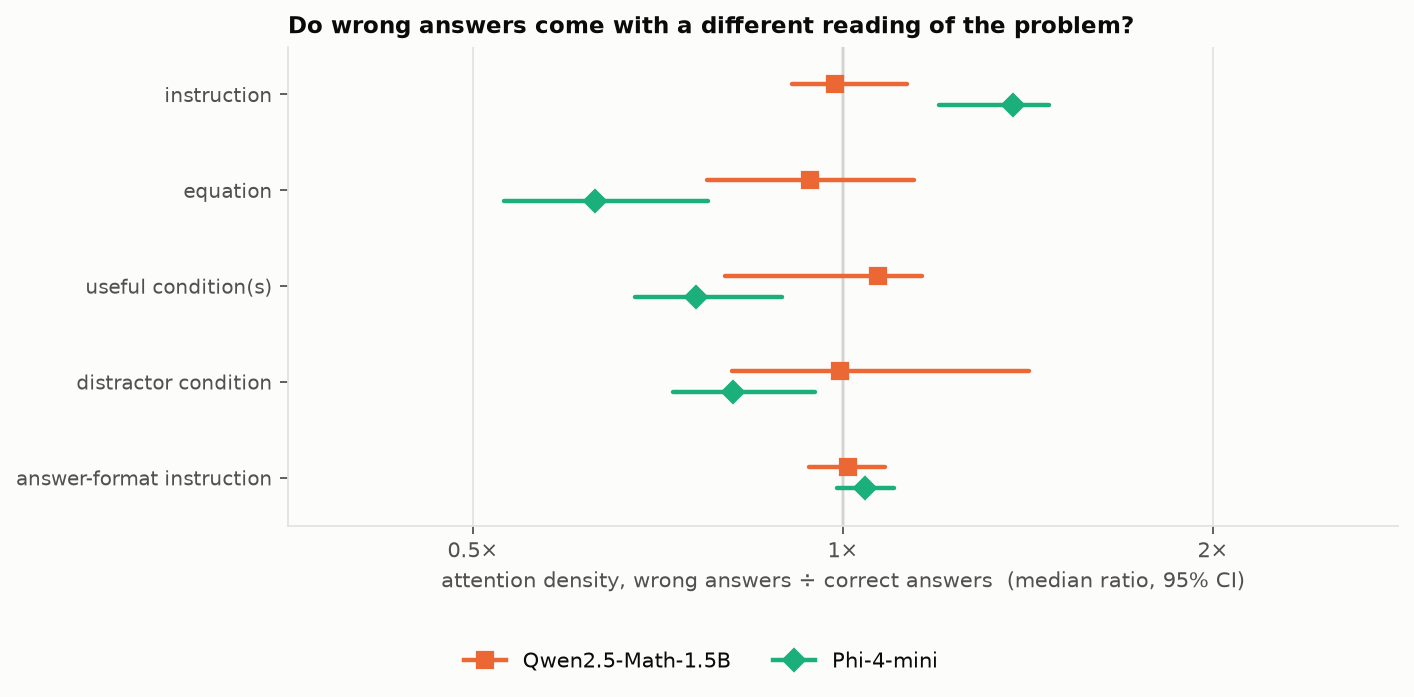

correct (median) wrong (median)  \
model             field                                                       
Qwen2.5-Math-1.5B instruction                           0.39           0.38   
                  equation                              0.91           0.86   
                  useful condition(s)                   0.95           1.02   
                  distractor condition                  0.80           0.80   
                  answer-format instruction             1.31           1.32   
Phi-4-mini        instruction                           2.54           3.49   
                  equation                              0.63           0.40   
                  useful condition(s)                   0.63           0.48   
                  distractor condition                  0.50           0.41   
                  answer-format instruction             1.07           1.12   

                                            wrong ÷ correct [95% CI]  \
model             field                                                
Qwen2.5-Math-1.5B instruction                      0.98 [0.91, 1.13]   
                  equation                         0.94 [0.78, 1.14]   
                  useful condition(s)              1.07 [0.80, 1.16]   
                  distractor condition             0.99 [0.81, 1.42]   
                  answer-format instruction        1.01 [0.94, 1.08]   
Phi-4-mini        instruction                      1.37 [1.20, 1.47]   
                  equation                         0.63 [0.53, 0.78]   
                  useful condition(s)              0.76 [0.68, 0.89]   
                  distractor condition             0.81 [0.73, 0.95]   
                  answer-format instruction        1.04 [0.99, 1.10]   

                                                                  n  
model             field                                              
Qwen2.5-Math-1.5B instruction                126 correct / 17 wrong  
                  equation                   126 correct / 17 wrong  
                  useful condition(s)        126 correct / 17 wrong  
                  distractor condition        94 correct / 13 wrong  
                  answer-format instruction  126 correct / 17 wrong  
Phi-4-mini        instruction                104 correct / 39 wrong  
                  equation                   104 correct / 39 wrong  
                  useful condition(s)        104 correct / 39 wrong  
                  distractor condition        80 correct / 27 wrong  
                  answer-format instruction  104 correct / 39 wrong

In [10]:
print('Not analysed (fewer than 10 wrong answers):', ', '.join(R['skipped_wrong']) or 'none')
show('wrong', 800)
T('wrong').set_index(['model', 'field'])

**Results**
- **Phi-4-mini (39 wrong of 143):** wrong answers come with less attention on the equation (0.63× [0.53, 0.78]), the
  useful conditions (0.76× [0.68, 0.89]) and the distractor (0.81× [0.73, 0.95]), and more on the instruction
  (1.37× [1.20, 1.47]). The answer-format instruction doesn't change (1.04×, interval includes 1).
- **Qwen2.5-Math (17 wrong of 143):** no difference in any field (0.94–1.07×, all intervals include 1).
- **Qwen3-4B:** 3 wrong answers among these items, too few to compare.

## Appendix A. Gradient-based methods (Gradient×Input, Integrated Gradients): not used
Both methods measure how the answer's log-probability **responds to changes in the input embeddings**:
Gradient×Input responds to an infinitesimal change at the input, and Integrated Gradients along a path of changed
inputs from a baseline. In a differential equation every symbol matters, and a small change gives a different
problem. The response to such changes therefore doesn't show what the model used to solve *this* problem. This is
the same reason LIME, SHAP and occlusion are excluded. The two methods were computed on the same items; the
figures below show how they behave here.

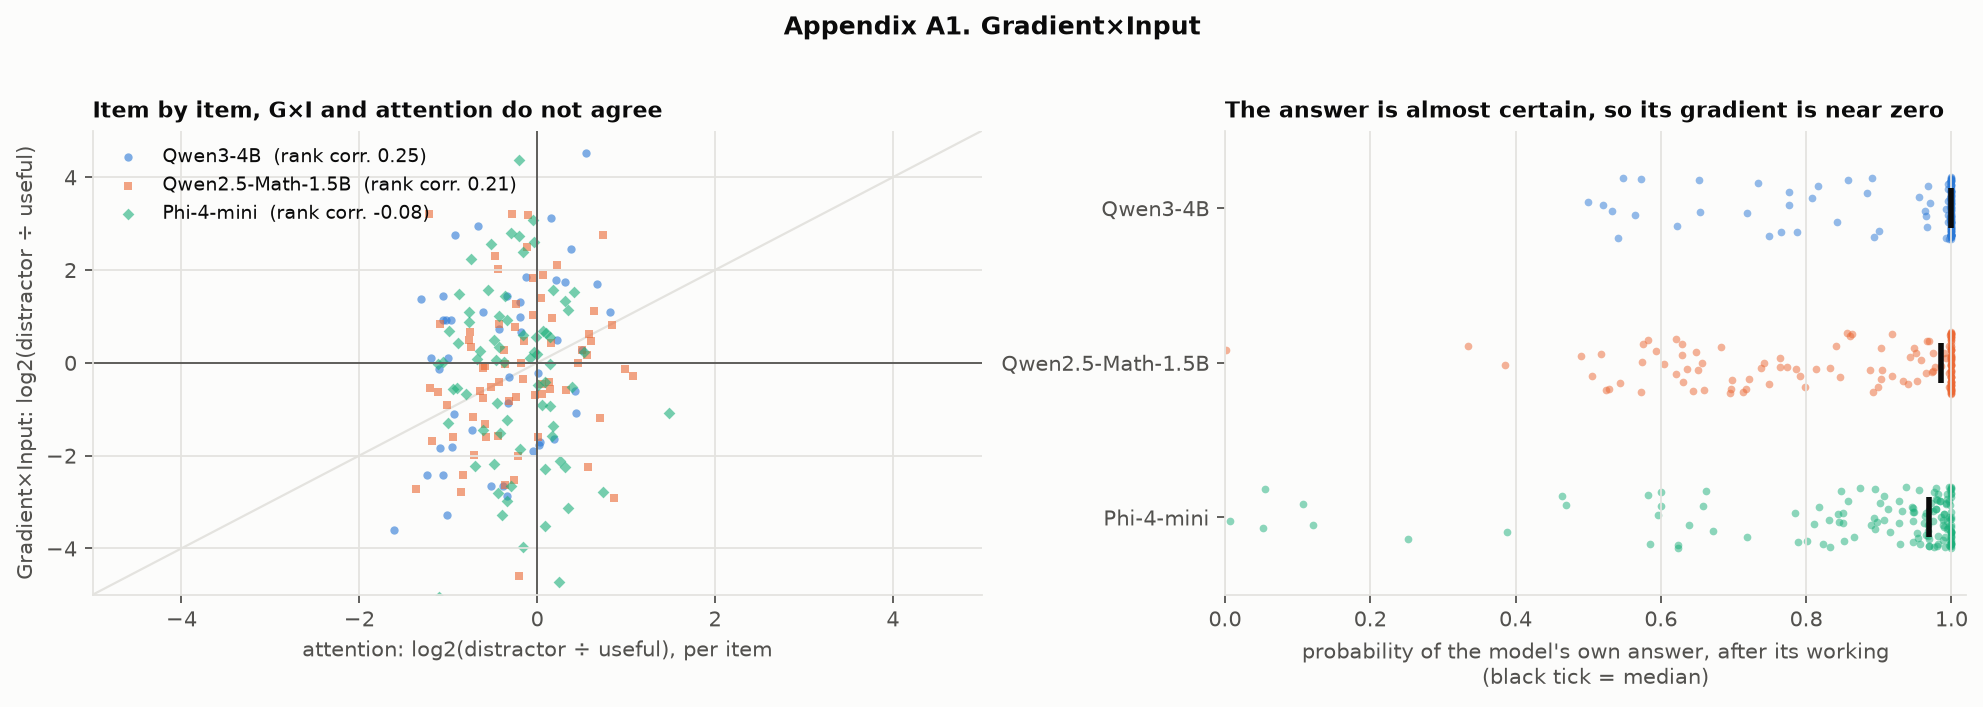

,"spread of distractor ratio, G×I (IQR, log2)","same, attention",rank corr. G×I vs attention,answers with p > 0.99,"G×I kept after cancellation, |Σ| ÷ Σ|·|"
model,,,,,
Qwen3-4B,3.08,1.10,0.25,76%,0.35
Qwen2.5-Math-1.5B,2.00,0.76,0.21,50%,0.32
Phi-4-mini,2.38,0.63,-0.08,32%,0.32


In [11]:
show('gxi')
T('gxi').set_index('model')

**Gradient×Input**
- Per item, its distractor ratio barely agrees with attention (rank correlation −0.08 to 0.25), and it is 2–5× more
  spread out (IQR 2.0–3.1 vs 0.6–1.1 in log2).
- The model's own answer is almost certain after its working (p > 0.99 for 32–76% of items). The gradient of log p
  shrinks towards zero as p approaches 1.
- Within a field, positive and negative token contributions cancel: only 32–35% of the summed magnitude remains.

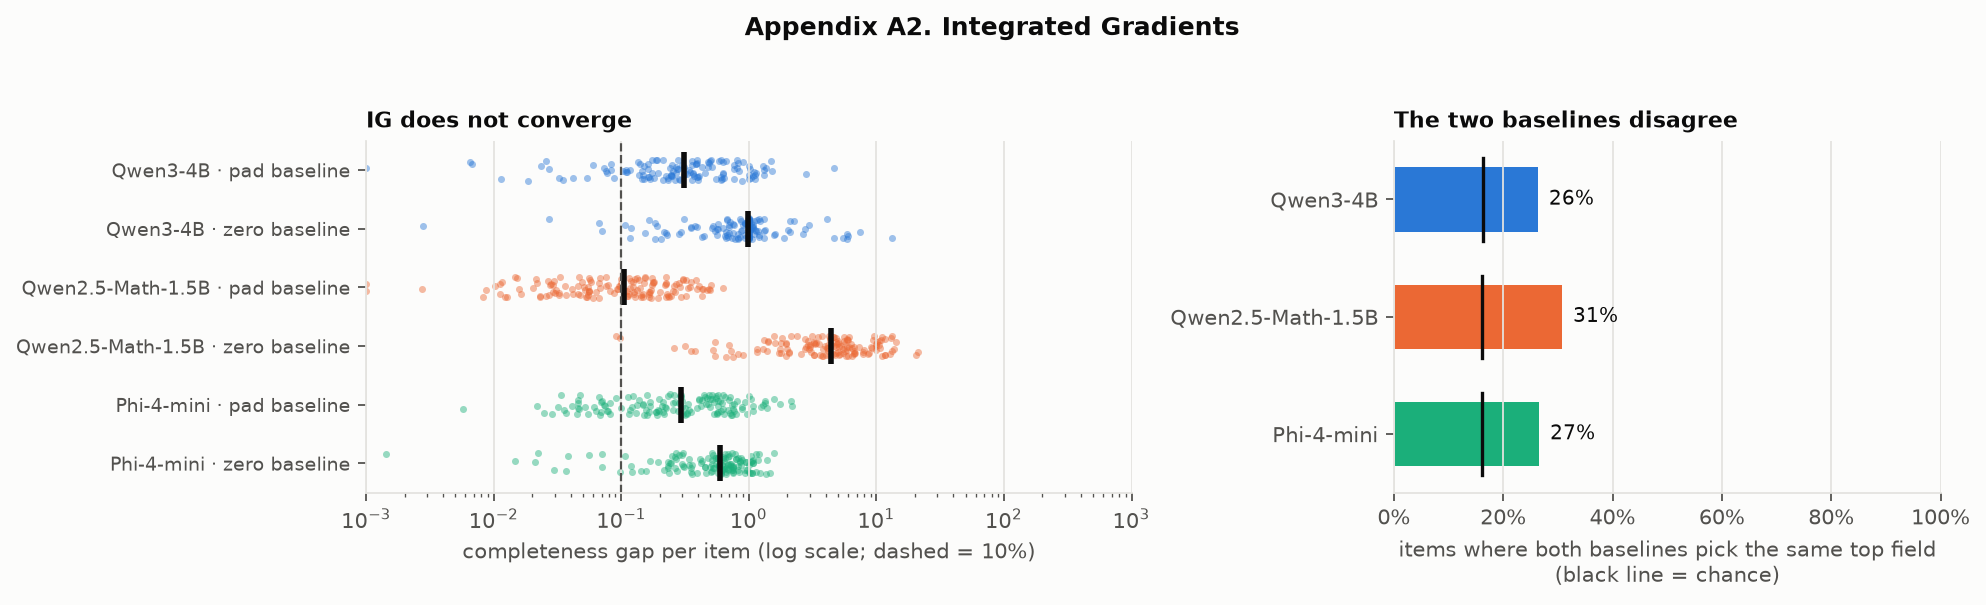

,IG steps,"median completeness gap, pad","median completeness gap, zero",pad vs zero: rank corr. of fields (median),pad vs zero: same top field
model,,,,,
Qwen3-4B,32,31%,99%,0.14,26% (chance 16%)
Qwen2.5-Math-1.5B,32,10%,441%,0.25,31% (chance 16%)
Phi-4-mini,32,30%,60%,0.37,27% (chance 16%)


In [12]:
show('ig')
T('ig').set_index('model')

**Integrated Gradients**
- The attributions don't add up to the change in the output: the median completeness gap is 10–31% with the pad
  baseline and 60–441% with the all-zero baseline (32 steps).
- The two baselines explain the same item differently: the rank correlation of their field attributions is
  0.14–0.37, and they agree on the top field in 26–31% of items (chance 16%).

## Appendix B. Notes on the data
- **Sample size:** 144 items per model (2 per category × subtype); 129 / 143 / 143 with a finished answer. Order
  groups have 16–42 items; correct-vs-wrong rests on 17 and 39 wrong answers.
- **Attention is averaged over heads** (and over layers, except in section 4); single heads can behave differently.
- **Precision:** Qwen2.5-Math ran in fp32 (fp16 overflowed in eager attention), the other two in fp16. All measures
  are ratios within an item.
- **`duplicate` items** are used only for the second-copy ÷ first-copy comparison. Which of the two identical copies
  the dataset labels "distractor" is arbitrary, so they are left out of the distractor ÷ useful comparisons.

In [13]:
# everything this notebook produced, in one zip (Kaggle: Output tab)
path = shutil.make_archive('attribution_report_a', 'zip', root_dir=OUT)
print('wrote', os.path.abspath(path), '(figures, CSV tables, stats.json)')

wrote D:\Study Material\Thesis\attribution_report_a.zip (figures, CSV tables, stats.json)
